# Paper Figures: Figure 1 - Movement (SIMBA) Analysis

This notebook generates publication-ready figures for the Bazzino & Roitman sodium appetite manuscript using data assembled by `src/assemble_all_data.py`.

**Figure 1: Behavioral (SIMBA) Analysis** — SIMBA analysis (appetitive) showing heatmaps and summary plots for replete and deplete conditions across sodium concentrations.

In [1]:
from pathlib import Path
import sys
# Add src to path for importing local modules
sys.path.insert(0, str(Path("../src").resolve()))
from data_io import load_assembled

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import stats


from trompy import save_figure_atomic
from extract_behav_parameters import smooth_array

from distance_matrix import (
    make_metric_matrix,
    get_group_matrix_diffs,
    GROUP_ORDER,
    GROUP_LABELS,
    compute_mds_coordinates,
    classify_groups_from_metric,
)

from figure_config import (
    configure_matplotlib,
    COLORS,
    HEATMAP_CMAP_DIV,
    HEATMAP_CMAP_RED,
    HEATMAP_CMAP_BLUE,
    DATAFOLDER,
    RESULTSFOLDER,
    FIGSFOLDER,
    SAVE_FIGS,
)
from figure_plotting import (
    smooth_array,
    get_heatmap_data,
    get_mean_snips,
    get_auc,
    init_heatmap_figure,
    init_snips_figure,
    make_heatmap,
    plot_snips,
    plot_auc_summary,
    calculate_ylims,
    make_correlation_plot_simba_1group,
    make_mds_plot,
    make_euclidean_distance_heatmap_all_rats,
    make_euclidean_distance_heatmap_averaged,
    make_confusion_matrix,
)

# Configure matplotlib
configure_matplotlib()
colors = COLORS  # Use shared color palette
custom_cmap_red = HEATMAP_CMAP_RED  # Use shared colormap
custom_cmap_blue = HEATMAP_CMAP_BLUE  # Use shared colormap

custom_cmap = HEATMAP_CMAP_DIV  # Use shared diverging colormap

SAVE_FIGS = True
SIMBA_METRIC = "median" # other options...

## Load Assembled Data

Load the complete dataset from the pickle file generated by the assembly script.

In [2]:
assembled_data_path = DATAFOLDER / "assembled"

data = load_assembled(assembled_data_path)

# Extract main components
x_array = data["x_array"]
snips_photo = data["snips_photo"]

if SIMBA_METRIC == "zscore":
    snips_simba = data["snips_simba_zscore"]
    simba_col = "simba_zscore_mean"
elif SIMBA_METRIC == "median":
    snips_simba = data["snips_simba_shifted_baseline"]
    simba_col = "simba_median_balance"
elif SIMBA_METRIC == "raw":
    snips_simba = data["snips_simba_raw"]
    simba_col = "simba_raw_mean"
    custom_cmap = HEATMAP_CMAP_RED  # Use red colormap for raw metric
else:
    raise ValueError(f"Unknown SIMBA_METRIC: {SIMBA_METRIC}")

params = data.get("params", {})
metadata = data.get("metadata", {})

print("Loaded assembled data from data/assembled")
print(f"\nData structure:")
print(f"  - x_array shape: {x_array.shape}")
print(f"  - snips_photo shape: {snips_photo.shape}")
print(f"  - snips_simba shape: {snips_simba.shape}")
print(f"  - x_array columns: {x_array.columns.tolist()}")
print(f"  - Number of trials: {len(x_array)}")

Loaded assembled data from data/assembled

Data structure:
  - x_array shape: (1960, 17)
  - snips_photo shape: (1960, 200)
  - snips_simba shape: (1960, 200)
  - x_array columns: ['trial', 'id', 'condition', 'infusiontype', 'sex', 'simba_raw_mean', 'simba_zscore_mean', 'simba_median_balance', 'auc_snips', 'auc_snips_early', 'auc_snips_late', 'time_moving', 'time_moving_raw', 'realigned_trials_da', 'realigned_trials_da_velocity', 'realigned_trials_behav', 'trial_aligned']
  - Number of trials: 1960


In [3]:
data.keys()

dict_keys(['x_array', 'snips_photo', 'snips_simba_raw', 'snips_simba_shifted_baseline', 'snips_simba_zscore', 'snips_simba_baseline', 'snips_simba', 'snips_movement', 'metadata', 'params', 'behav_stats', 'snips_movement_raw'])

## Figure 1: Behavioral Analysis — SIMBA Metrics

Analysis of behavioral responses (movement) showing heatmaps, snip time series, and summary AUC metrics across replete and deplete sodium conditions, separated by infusion type (10NaCl vs 45NaCl).

In [4]:
snips_to_plot = np.array(smooth_array(snips_simba))  # Use smoothed and z-scored data for all subsequent analyses and plotting

# Parameters for visualization - MOVEMENT
# Use dynamic scaling based on actual data ranges (asymmetric, not symmetric)
# This ensures heatmaps use the full range of your data without artificial symmetry
vmin = np.nanpercentile(snips_to_plot, 5)  # 5th percentile for lower bound
vmax = np.nanpercentile(snips_to_plot, 95)  # 95th percentile for upper bound
print(f"Calculated asymmetric vlims: vmin={vmin:.4f}, vmax={vmax:.4f}")

if SIMBA_METRIC == "zscore":
    vlim = (-1, 1)
elif SIMBA_METRIC == "median":
    vlim = (-0.2, 0.2)
elif SIMBA_METRIC == "raw":
    vlim = (0, 0.4)  # Use calculated asymmetric limits for raw metric
else:
    vlim = (vmin, vmax)  # Use calculated asymmetric limits for other metrics

# Calculate dynamic y-limits based on all snips data - MOVEMENT
print("\n" + "="*60)
print("CALCULATING Y-LIMITS FOR TIME SERIES PLOTS")
print("="*60)

# Get all condition/infusion combinations to compute limits
rep_10, rep_45 = get_mean_snips(snips_to_plot, x_array, "replete")
dep_10, dep_45 = get_mean_snips(snips_to_plot, x_array, "deplete")

# Calculate y-limits based on all snips with 5% padding
calc_ylims = calculate_ylims([rep_10, rep_45, dep_10, dep_45], pad_percentage=5)

print(f"  Data range (min, max): ({np.nanmin(snips_to_plot):.4f}, {np.nanmax(snips_to_plot):.4f})")
print(f"  Calculated y-limits: {calc_ylims}")
print("="*60 + "\n")



Calculated asymmetric vlims: vmin=-0.1680, vmax=0.2795

CALCULATING Y-LIMITS FOR TIME SERIES PLOTS


  Data range (min, max): (-0.3044, 0.6933)
  Calculated y-limits: (np.float64(-0.15188435147959184), np.float64(0.24586074127551028))



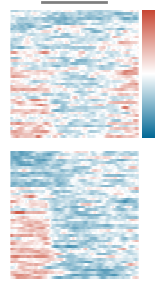

In [5]:
### 1A. Heatmaps — Replete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Replete + 10NaCl
heatmap_data_rep_10 = get_heatmap_data(snips_to_plot, x_array, "replete", "10NaCl")
replete_10_auc = get_auc(heatmap_data_rep_10)
make_heatmap(heatmap_data_rep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap)

# Replete + 45NaCl
heatmap_data_rep_45 = get_heatmap_data(snips_to_plot, x_array, "replete", "45NaCl")
replete_45_auc = get_auc(heatmap_data_rep_45)
make_heatmap(heatmap_data_rep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_heatmap_simba_replete", FIGSFOLDER)

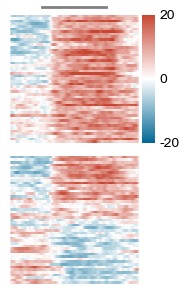

In [6]:
### 1B. Heatmaps — Deplete Condition

f, ax1, ax2, cbar_ax = init_heatmap_figure()

# Deplete + 10NaCl
heatmap_data_dep_10 = get_heatmap_data(snips_to_plot, x_array, "deplete", "10NaCl")
deplete_10_auc = get_auc(heatmap_data_dep_10)
make_heatmap(heatmap_data_dep_10, ax1, vlim, inf_bar=True, cmap=custom_cmap)

# Deplete + 45NaCl
heatmap_data_dep_45 = get_heatmap_data(snips_to_plot, x_array, "deplete", "45NaCl")
deplete_45_auc = get_auc(heatmap_data_dep_45)
make_heatmap(heatmap_data_dep_45, ax2, vlim, cbar_ax=cbar_ax, cmap=custom_cmap)

cbar_ax.tick_params(axis='both', length=0)
if SIMBA_METRIC == "zscore":
    cbar_ax.set_yticks((-1, 0, 1), labels=["-1", "0", "1"])
elif SIMBA_METRIC == "median":
    cbar_ax.set_yticks((-0.2, 0, 0.2), labels=["-20", "0", "20"])
elif SIMBA_METRIC == "raw":
    cbar_ax.set_yticks((0, 0.4))

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_heatmap_simba_deplete", FIGSFOLDER)

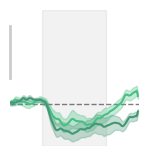

In [7]:
### 1C. Time Series Snips — Replete Condition
if SIMBA_METRIC == "zscore":
    ylims = (-0.5, 1)
    yscalebar=[0.3, 0.8]
elif SIMBA_METRIC == "median":
    ylims = (-0.08, 0.18)
    yscalebar=[0.05, 0.15]
elif SIMBA_METRIC == "raw":
    ylims = (0, 0.4)
    yscalebar=[0.1, 0.3]
else:
    ylims = calc_ylims
    yscalebar=[0.3, 0.8]
    
# Get animal-averaged snips for replete
snips_rep_10, snips_rep_45 = get_mean_snips(snips_to_plot, x_array, "replete")

f, ax = init_snips_figure()
plot_snips(snips_rep_10, snips_rep_45, ax, colors[0], colors[1], ylims, yscalebar=yscalebar, xscalebar=False)
ax.axhline(0, color="black", lw=1, ls="--", alpha=0.5, zorder=0)
ax.axvspan(5, 15, color="k", alpha=0.05, zorder=-10)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_snips_simba_replete", FIGSFOLDER)

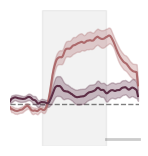

In [8]:
### 1D. Time Series Snips — Deplete Condition

# Get animal-averaged snips for deplete
snips_dep_10, snips_dep_45 = get_mean_snips(snips_to_plot, x_array, "deplete")

f, ax = init_snips_figure()
plot_snips(snips_dep_10, snips_dep_45, ax, colors[2], colors[3], ylims, xscalebar=True)  # Add scale bar for deplete condition
ax.axhline(0, color="black", lw=1, ls="--", alpha=0.5, zorder=0)
ax.axvspan(5, 15, color="k", alpha=0.05, zorder=-10)

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_snips_simba_deplete", FIGSFOLDER)

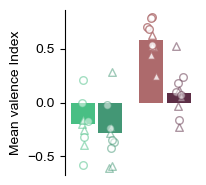

In [9]:
### 1E. AUC Summary — Bar Plot with Individual Data Points

def get_auc_and_sex_by_group(x_array, condition, infusiontype, simba_col="mean_simba"):
    grouped = (
        x_array
        .query("condition == @condition and infusiontype == @infusiontype")
        .groupby("id", sort=True)
        .agg(
            simba_col=(simba_col, "mean"),
            sex=("sex", "first"),
        )
    )
    auc_vals = grouped["simba_col"].to_numpy()
    sex_vals = grouped["sex"].fillna("Unknown").to_numpy()
    return auc_vals, sex_vals

ylabel = "Mean valence Index"

# Organize AUCs by condition
replete_10_auc, replete_10_sex = get_auc_and_sex_by_group(x_array, "replete", "10NaCl", simba_col=simba_col)
replete_45_auc, replete_45_sex = get_auc_and_sex_by_group(x_array, "replete", "45NaCl", simba_col=simba_col)
deplete_10_auc, deplete_10_sex = get_auc_and_sex_by_group(x_array, "deplete", "10NaCl", simba_col=simba_col)
deplete_45_auc, deplete_45_sex = get_auc_and_sex_by_group(x_array, "deplete", "45NaCl", simba_col=simba_col)

replete_aucs = [replete_10_auc, replete_45_auc]
deplete_aucs = [deplete_10_auc, deplete_45_auc]
aucs = [replete_aucs, deplete_aucs]

sex_groups = [
    [replete_10_sex, replete_45_sex],
    [deplete_10_sex, deplete_45_sex],
]

f, ax = plot_auc_summary(
    aucs,
    colors,
    figsize=(2.2, 2.2),
    ylabel=ylabel,
    sex_groups=sex_groups,
    sex_markers={"M": "^", "F": "o"}
 )

if SAVE_FIGS:
    save_figure_atomic(f, "fig1_auc_simba_summary", FIGSFOLDER)

In [10]:
# 1E stats: one-sample tests against zero (no sex factor)
from stats_helpers import (
    one_sample_wilcoxon_table,
    prepare_mixedlm_auc_df,
    fit_mixedlm_with_fallback,
    omnibus_wald_table,
    posthoc_pairwise_auc,
    holm_matrix_from_posthoc,
)

# We evaluated both parametric and non-parametric one-sample approaches.
# Non-parametric testing was more appropriate for these AUC distributions,
# so we use Wilcoxon signed-rank tests for all groups for consistency.
group_data = {
    "Replete + 10NaCl": replete_aucs[0],
    "Replete + 45NaCl": replete_aucs[1],
    "Deplete + 10NaCl": deplete_aucs[0],
    "Deplete + 45NaCl": deplete_aucs[1],
}

stats_df = one_sample_wilcoxon_table(group_data)
print("Figure 1E — One-sample Wilcoxon signed-rank tests against zero (sex not included as a factor)")
display(stats_df)

Figure 1E — One-sample Wilcoxon signed-rank tests against zero (sex not included as a factor)


,Group,n,Mean,Median,SD,Test,Statistic,p-value,Note
0,Replete + 10NaCl,10,-0.2016,-0.1812,0.2142,wilcoxon signed-rank,6.0,0.0273,
1,Replete + 45NaCl,10,-0.2827,-0.3141,0.2619,wilcoxon signed-rank,4.0,0.0137,
2,Deplete + 10NaCl,10,0.5836,0.5786,0.1669,wilcoxon signed-rank,0.0,0.0020,
3,Deplete + 45NaCl,10,0.0862,0.0810,0.2095,wilcoxon signed-rank,15.0,0.2324,


In [11]:
# 1E omnibus model (ANOVA-like): condition within-subject, infusiontype/sex between-subject
# Build subject-by-condition dataset from averaged SIMBA metric
model_df = prepare_mixedlm_auc_df(x_array, value_col=simba_col)

print(f"Subjects included in omnibus model: {model_df['id'].nunique()}")
print(f"Rows (subject x condition): {len(model_df)}")

mixed_res, model_formula_used, model_fit_errors = fit_mixedlm_with_fallback(model_df)
if mixed_res is None:
    print("\nFigure 1E omnibus model could not be fit (all candidate models failed).")
    print("Model-fit errors:")
    for formula, err in model_fit_errors:
        print(f"  - {formula}: {err}")
else:
    print(f"\nFigure 1E omnibus model fitted with formula: {model_formula_used}")
    print("Fixed-effects omnibus tests (Wald):")
    try:
        display(omnibus_wald_table(mixed_res))
    except Exception:
        print("wald_test_terms not available; showing fixed-effects coefficient table instead.")
        display(mixed_res.summary().tables[1])

Subjects included in omnibus model: 20
Rows (subject x condition): 40

Figure 1E omnibus model fitted with formula: auc ~ C(condition) * C(infusiontype) * C(sex)
Fixed-effects omnibus tests (Wald):


,Term,statistic,pvalue,df_constraint
0,Intercept,[[3.8762881466247676]],0.04897271588461747,1
1,C(condition),[[114.96662653191825]],8.003310527962847e-27,1
2,C(infusiontype),[[0.750094345139866]],0.3864463621871359,1
3,C(sex),[[0.21433330448382248]],0.6433919992780652,1
4,C(condition):C(infusiontype),[[19.3806325699662]],1.0708759232210643e-05,1
5,C(condition):C(sex),[[2.142269542237994]],0.14328976979313993,1
6,C(infusiontype):C(sex),[[0.09023590571528174]],0.7638774643441304,1
7,C(condition):C(infusiontype):C(sex),[[1.1888751967033724]],0.27555655988995714,1


In [12]:
# 1E mixed ANOVA: condition (within) × infusiontype × sex (between)
# 3-way interaction (condition × infusiontype × sex) excluded — sex is included
# as a main effect and in 2-way interactions but the 3-way is pooled into error.
#
# Implemented via OLS decomposition (mathematically equivalent to standard mixed ANOVA):
#   Between-subjects effects  →  OLS on per-subject means (collapsed over condition)
#   Within-subjects effects   →  OLS on condition contrast (deplete − replete)

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
import numpy as np
import pandas as pd
from scipy import stats

# Pivot to wide format: one row per subject
wide_df = model_df.pivot_table(
    index=["id", "infusiontype", "sex"],
    columns="condition",
    values="auc",
).reset_index()
wide_df.columns.name = None
n_s = len(wide_df)

# Between-subjects partition: OLS on per-subject means
# Full factorial between factors (infusiontype × sex interaction retained)
wide_df["subj_mean"] = wide_df[["replete", "deplete"]].mean(axis=1)
bw_fit = smf.ols("subj_mean ~ C(infusiontype) * C(sex)", data=wide_df).fit()

# Within-subjects partition: OLS on condition contrast (deplete − replete)
# No 3-way: use additive model for within × between interactions
wide_df["cond_diff"] = wide_df["deplete"] - wide_df["replete"]
wi_fit = smf.ols("cond_diff ~ C(infusiontype) + C(sex)", data=wide_df).fit()

# Condition main effect F (computed manually from the within-subjects error)
mean_d = wide_df["cond_diff"].mean()
F_C = n_s * mean_d ** 2 / wi_fit.mse_resid
p_C = stats.f.sf(F_C, dfn=1, dfd=wi_fit.df_resid)

def _label(s):
    return (s.replace("C(infusiontype)", "infusiontype")
             .replace("C(sex)", "sex")
             .replace(":", " × "))

rows = []
for src, row in anova_lm(bw_fit, typ=2).iterrows():
    if src == "Residual":
        rows.append({"Source": "  Error (between-subjects)", "df": int(row["df"]),
                     "F": np.nan, "p": np.nan})
    else:
        rows.append({"Source": _label(src), "df": int(row["df"]),
                     "F": row["F"], "p": row["PR(>F)"]})

rows.append({"Source": "condition", "df": 1, "F": F_C, "p": p_C})

for src, row in anova_lm(wi_fit, typ=2).iterrows():
    if src == "Residual":
        rows.append({"Source": "  Error (within-subjects)", "df": int(row["df"]),
                     "F": np.nan, "p": np.nan})
    else:
        rows.append({"Source": "condition × " + _label(src), "df": int(row["df"]),
                     "F": row["F"], "p": row["PR(>F)"]})

aov_table = pd.DataFrame(rows).set_index("Source")

print("Mixed ANOVA  (condition: within | infusiontype, sex: between; 3-way interaction excluded)")
print(f"N = {n_s} subjects | Between-error df = {int(bw_fit.df_resid)} | "
      f"Within-error df = {int(wi_fit.df_resid)}\n")
display(aov_table.round(4))

Mixed ANOVA  (condition: within | infusiontype, sex: between; 3-way interaction excluded)
N = 20 subjects | Between-error df = 16 | Within-error df = 17



,df,F,p
Source,,,
infusiontype,1,11.0398,0.0043
sex,1,0.6614,0.4280
infusiontype × sex,1,0.6568,0.4296
Error (between-subjects),16,NaN,NaN
condition,1,162.6693,0.0000
condition × infusiontype,1,21.1596,0.0003
condition × sex,1,0.7698,0.3925
Error (within-subjects),17,NaN,NaN


In [13]:
# Export JASP-ready data for mixed ANOVA
# Saves both wide (recommended for repeated-measures setup in JASP) and long formats.

jasp_outdir = RESULTSFOLDER
jasp_outdir.mkdir(parents=True, exist_ok=True)

# Wide format: one row per subject, between factors as columns,
# repeated-measures levels as separate dependent-variable columns.
jasp_wide = (
    model_df
    .pivot_table(index=["id", "infusiontype", "sex"], columns="condition", values="auc")
    .reset_index()
)
jasp_wide.columns.name = None
jasp_wide = jasp_wide.rename(columns={
    "replete": "auc_replete",
    "deplete": "auc_deplete",
})

# Long format: one row per subject x condition
jasp_long = model_df[["id", "infusiontype", "sex", "condition", "auc"]].copy()

wide_path = jasp_outdir / "figure1_mixed_anova_jasp_wide.csv"
long_path = jasp_outdir / "figure1_mixed_anova_jasp_long.csv"

jasp_wide.to_csv(wide_path, index=False)
jasp_long.to_csv(long_path, index=False)

print("Saved JASP export files:")
print(f"  - {wide_path.relative_to(RESULTSFOLDER.parent).as_posix()}")
print(f"  - {long_path.relative_to(RESULTSFOLDER.parent).as_posix()}")
print("\nWide format columns:", list(jasp_wide.columns))
print("Long format columns:", list(jasp_long.columns))

display(jasp_wide.head())

Saved JASP export files:
  - results/figure1_mixed_anova_jasp_wide.csv
  - results/figure1_mixed_anova_jasp_long.csv

Wide format columns: ['id', 'infusiontype', 'sex', 'auc_replete', 'auc_deplete']
Long format columns: ['id', 'infusiontype', 'sex', 'condition', 'auc']


,id,infusiontype,sex,auc_replete,auc_deplete
0,PB23,10NaCl,F,-0.005714,0.788980
1,PB24,10NaCl,F,0.212245,0.697143
2,PB26,45NaCl,M,0.281633,0.523265
3,PB27,45NaCl,M,-0.602857,-0.223265
4,PB30,45NaCl,F,-0.026122,0.236327


In [14]:
# 1E posthoc pairwise tests across 4 groups (ignoring sex) with multiple-comparison correction
posthoc_results, groups = posthoc_pairwise_auc(x_array, value_col=simba_col)

print("Posthoc pairwise tests across 4 groups (sex ignored), Holm-corrected")
display(posthoc_results.sort_values("p_holm", na_position="last"))

# Compact 4x4 matrix view of Holm-adjusted p-values
p_matrix = holm_matrix_from_posthoc(posthoc_results, groups)
print("\nCompact matrix: Holm-adjusted p-values")
display(p_matrix)

Posthoc pairwise tests across 4 groups (sex ignored), Holm-corrected


,Comparison,Test,n1,n2,n_pairs,Statistic,p_raw,Note,p_holm,reject_holm_0.05
2,deplete | 10NaCl vs replete | 45NaCl,Mann-Whitney U (unpaired),10,10,NaN,99.0,0.0002,,0.0015,True
0,deplete | 10NaCl vs deplete | 45NaCl,Mann-Whitney U (unpaired),10,10,NaN,97.0,0.0004,,0.0022,True
1,deplete | 10NaCl vs replete | 10NaCl,Wilcoxon signed-rank (paired),10,10,10.0,0.0,0.0020,,0.0078,True
4,deplete | 45NaCl vs replete | 45NaCl,Wilcoxon signed-rank (paired),10,10,10.0,0.0,0.0020,,0.0078,True
3,deplete | 45NaCl vs replete | 10NaCl,Mann-Whitney U (unpaired),10,10,NaN,84.0,0.0113,,0.0227,True
5,replete | 10NaCl vs replete | 45NaCl,Mann-Whitney U (unpaired),10,10,NaN,66.0,0.2413,,0.2413,False



Compact matrix: Holm-adjusted p-values


,deplete | 10NaCl,deplete | 45NaCl,replete | 10NaCl,replete | 45NaCl
deplete | 10NaCl,0.0000,0.0022,0.0078,0.0015
deplete | 45NaCl,0.0022,0.0000,0.0227,0.0078
replete | 10NaCl,0.0078,0.0227,0.0000,0.2413
replete | 45NaCl,0.0015,0.0078,0.2413,0.0000


In [15]:
### Correlation plots — Time moving across trials

def make_auc_data_per_trial(x_array, condition, infusiontype, simba_col):
    return (
        x_array
        .query("condition == @condition & infusiontype == @infusiontype")
        .groupby("trial")[simba_col]
        .mean()
        .values
    )
    
replete_10 = make_auc_data_per_trial(x_array, "replete", "10NaCl", simba_col)
replete_45 = make_auc_data_per_trial(x_array, "replete", "45NaCl", simba_col)
deplete_10 = make_auc_data_per_trial(x_array, "deplete", "10NaCl", simba_col)
deplete_45 = make_auc_data_per_trial(x_array, "deplete", "45NaCl", simba_col)

# f = make_correlation_plot_simba(replete_10, replete_45, colors[0], colors[1], yaxis=True)
# if SAVE_FIGS:
#     save_figure_atomic(f, "fig1_correlation_simba_replete", FIGSFOLDER)
    
# f = make_correlation_plot_simba(deplete_10, deplete_45, colors[2], colors[3])
# if SAVE_FIGS:
#     save_figure_atomic(f, "fig1_correlation_simba_deplete", FIGSFOLDER)

r = 0.48, p = 0.000
r = -0.09, p = 0.528
r = -0.20, p = 0.160


Sigmoid fit parameters: L=-0.66, k=0.31, x0=22.61, b=0.44


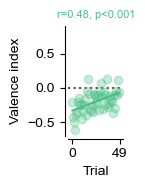

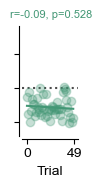

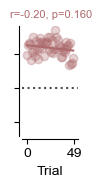

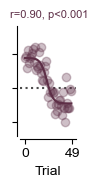

In [16]:
f, ax = make_correlation_plot_simba_1group(replete_10, colors[0], yaxis=True, simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_replete10", FIGSFOLDER)
    
f, ax = make_correlation_plot_simba_1group(replete_45, colors[1], simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_replete45", FIGSFOLDER)
    
f, ax = make_correlation_plot_simba_1group(deplete_10, colors[2], simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_deplete10", FIGSFOLDER)
    
f, ax = make_correlation_plot_simba_1group(deplete_45, colors[3], fit="sigmoid", simba_metric=SIMBA_METRIC)
if SAVE_FIGS:
    save_figure_atomic(f, "fig1_correlation_simba_deplete45", FIGSFOLDER)

In [17]:
### Model fits on time-moving by trial data with fit-quality checks
from model_fit_helpers import run_model_fit_comparison

fit_inputs = {
    "Replete + 10NaCl": replete_10,
    "Replete + 45NaCl": replete_45,
    "Deplete + 10NaCl": deplete_10,
    "Deplete + 45NaCl": deplete_45,
}

fit_results, sigmoid_params_table = run_model_fit_comparison(
    fit_inputs,
    models=("linear", "sigmoidal"),
)

print("Model fit results (AUC_simba by trial; linear + sigmoidal only) with quality checks:")
display(fit_results)

print("Sigmoidal fit parameters (AUC_simba by trial) with validity checks:")
display(sigmoid_params_table)

Model fit results (AUC_simba by trial; linear + sigmoidal only) with quality checks:


,Condition,Model,r,p,RMSE,AICc,BIC,Sigmoid_valid,Sigmoid_flags,AICc_rank,Best_by_AICc
0,Replete + 10NaCl,Linear,0.4840,0.0004,0.1376,-190.1443,-186.6215,NaN,,1.0,True
1,Replete + 10NaCl,Sigmoidal,0.5280,0.0001,0.1335,-188.4305,-181.7723,False,x0_interior;asymptotes_covered,2.0,False
2,Replete + 45NaCl,Linear,0.0924,0.5276,0.1370,-190.5174,-186.9946,NaN,,1.0,True
3,Replete + 45NaCl,Sigmoidal,0.0924,0.5277,0.1370,-185.8691,-179.2109,False,k_plausible;asymptotes_covered,2.0,False
4,Deplete + 10NaCl,Linear,0.2040,0.1598,0.1105,-211.6368,-208.1140,NaN,,2.0,False
5,Deplete + 10NaCl,Sigmoidal,0.4099,0.0034,0.1029,-213.9199,-207.2617,False,k_plausible,1.0,True
6,Deplete + 45NaCl,Linear,0.8424,0.0000,0.1696,-169.6079,-166.0852,NaN,,2.0,False
7,Deplete + 45NaCl,Sigmoidal,0.9016,0.0000,0.1362,-186.4753,-179.8171,True,ok,1.0,True


Sigmoidal fit parameters (AUC_simba by trial) with validity checks:


,Condition,L,k,x0,b,Sigmoid_valid,Sigmoid_flags,x0_interior,k_plausible,amp_plausible,ci_finite,asymptotes_covered
0,Replete + 10NaCl,0.3548,0.1717,7.8460,-0.4927,False,x0_interior;asymptotes_covered,False,True,True,True,False
1,Replete + 45NaCl,-4.0554,0.0009,30.8822,1.7397,False,k_plausible;asymptotes_covered,True,False,True,True,False
2,Deplete + 10NaCl,0.1028,-21.2183,35.0628,0.5106,False,k_plausible,True,False,True,True,True
3,Deplete + 45NaCl,-0.6626,0.3104,23.6086,0.4363,True,ok,True,True,True,True,True


In [18]:
### Best valid model per condition (compact summary)
from model_fit_helpers import summarize_best_valid_model

best_model_summary = summarize_best_valid_model(fit_results)

print("Best valid model per condition (AICc-based):")
display(best_model_summary)

Best valid model per condition (AICc-based):


,Condition,Selected_Model,Selection_Reason,r,p,RMSE,AICc,BIC,Sigmoid_valid,Sigmoid_flags
0,Deplete + 10NaCl,Linear,linear_default_or_nonlinear_failed_gate,0.2040,0.1598,0.1105,-211.6368,-208.1140,NaN,
1,Deplete + 45NaCl,Sigmoidal,nonlinear_passed_gate_and_best_AICc,0.9016,0.0000,0.1362,-186.4753,-179.8171,True,ok
2,Replete + 10NaCl,Linear,linear_default_or_nonlinear_failed_gate,0.4840,0.0004,0.1376,-190.1443,-186.6215,NaN,
3,Replete + 45NaCl,Linear,linear_default_or_nonlinear_failed_gate,0.0924,0.5276,0.1370,-190.5174,-186.9946,NaN,


## Euclidean distances

In [19]:
# prepare distance matrix for heatplots and MDS plot
matrix, series_labels, _, group_to_row_indices = make_metric_matrix(x_array, "simba_median_balance", GROUP_ORDER, GROUP_LABELS)

group_sizes = {GROUP_LABELS[group_key]: len(indices) for group_key, indices in group_to_row_indices.items()}
group_boundaries = np.cumsum([len(group_to_row_indices[group_key]) for group_key in GROUP_ORDER])

distances, group_distance_matrix = get_group_matrix_diffs(matrix, series_labels, group_to_row_indices)

Trials per animal/group series:
                   count  min  max
group_key                         
(deplete, 10NaCl)     10   49   49
(deplete, 45NaCl)     10   49   49
(replete, 10NaCl)     10   49   49
(replete, 45NaCl)     10   49   49
Metric matrix shape: (40, 49)
Distance input shape: (40, 49)
Series per group:
{'Deplete 10NaCl': 10, 'Deplete 45NaCl': 10, 'Replete 10NaCl': 10, 'Replete 45NaCl': 10}
Distance metric: euclidean
Mean off-diagonal distance: 6.2295


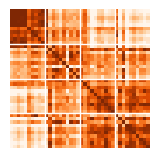

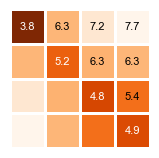

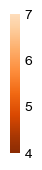

In [20]:
# make euclidiean distance heatplots

fig, ax = make_euclidean_distance_heatmap_all_rats(distances, group_boundaries=group_boundaries)
if SAVE_FIGS:
    save_figure_atomic(fig, "fig1_heatmap_euclidean_all_rats", FIGSFOLDER)
    
# Toggle redundant annotation labels on/off for symmetric matrix plots.
# keep_triangle options: "upper" or "lower"
fig, ax, fig_cbar, ax_cbar = make_euclidean_distance_heatmap_averaged(
    group_distance_matrix,
    remove_redundant_labels=True,
    keep_triangle="upper",
 )
ax_cbar.set_ylim([4,7])

if SAVE_FIGS:
    save_figure_atomic(fig, "fig1_heatmap_euclidean_averaged", FIGSFOLDER)
    save_figure_atomic(fig_cbar, "fig1_heatmap_euclidean_averaged_cbar", FIGSFOLDER)

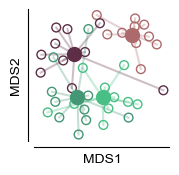

In [21]:
# make MDS plot for photometry data
coords = compute_mds_coordinates(distances)

fig, ax = make_mds_plot(coords, group_to_row_indices, reverse_axes="x")

if SAVE_FIGS:
    save_figure_atomic(fig, "fig1_mds_plot", FIGSFOLDER)

Feature matrix shape (n_samples, n_trials): (40, 49)
Unique class labels: ['Deplete 10NaCl' 'Deplete 45NaCl' 'Replete 10NaCl' 'Replete 45NaCl']
Unique rats: 20
Leave-One-Rat-Out CV accuracy: 0.625
                precision    recall  f1-score   support

Deplete 10NaCl       0.82      0.90      0.86        10
Deplete 45NaCl       0.60      0.60      0.60        10
Replete 10NaCl       0.56      0.50      0.53        10
Replete 45NaCl       0.50      0.50      0.50        10

      accuracy                           0.62        40
     macro avg       0.62      0.62      0.62        40
  weighted avg       0.62      0.62      0.62        40



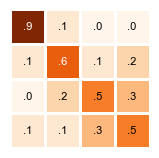

In [22]:
# use classifier to predict group labels from behaviour data and make confusion matrix

metric_col = "simba_median_balance"
results = classify_groups_from_metric(
    x_array=x_array,
    metric_col=metric_col,
    group_order=GROUP_ORDER,
    group_labels=GROUP_LABELS,
    smooth_features=False,
    expected_n_trials=49,
    normalize="true",
)

X = results["X"]
y = results["y"]
rat_groups = results["rat_groups"]
metric_matrix_df = results["metric_matrix_df"]
cm = results["cm"]

print("Feature matrix shape (n_samples, n_trials):", X.shape)
print("Unique class labels:", np.unique(y))
print("Unique rats:", len(np.unique(rat_groups)))
print(f"Leave-One-Rat-Out CV accuracy: {results['accuracy']:.3f}")
print(results["report_text"])

# Toggle redundant annotation labels on/off for symmetric matrix plots.
# keep_triangle options: "upper" or "lower"
fig, ax, fig_cbar, ax_cbar = make_confusion_matrix(
    cm,
)
save_figure_atomic(fig, "fig1_confusion_matrix", FIGSFOLDER)

ax_cbar.set_yticks([])
save_figure_atomic(fig_cbar, "fig1_confusion_matrix_cbar", FIGSFOLDER)

In [23]:
# Binomial test: classifier accuracy vs chance level
from scipy.stats import binomtest

n_total = len(y)
n_classes = len(np.unique(y))
chance_level = 1.0 / n_classes
n_correct = int(round(results["accuracy"] * n_total))

binom_res = binomtest(k=n_correct, n=n_total, p=chance_level, alternative="greater")

print(f"n_total = {n_total}")
print(f"n_correct = {n_correct}")
print(f"accuracy = {results['accuracy']:.3f}")
print(f"chance level = {chance_level:.3f}")
print(f"one-sided binomial p-value = {binom_res.pvalue:.12g}")

n_total = 40
n_correct = 25
accuracy = 0.625
chance level = 0.250
one-sided binomial p-value = 5.87965935821e-07


Saved legend swatch figures:
  - legend_pies_replete.pdf
  - legend_pies_deplete.pdf


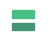

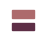

In [24]:
### Figure 1 legend swatches (pie-style legend exports)

from matplotlib.patches import Patch

groups = ["", ""]

# Replete swatches (match archived spacing/placement exactly)
f, ax = plt.subplots(figsize=(0.35, 0.25), gridspec_kw={"left": 0.01, "right": 0.99})

legend_patches = []
for color, text in zip(colors[:2], groups):
    patch = Patch(color=color, label=text)
    legend_patches.append(patch)

ax.legend(
    handles=legend_patches,
    loc="center",
    fontsize=8,
    frameon=False,
    labelspacing=0.2,
    borderpad=0.05,
    )
ax.axis("off")

if SAVE_FIGS:
    f.savefig(FIGSFOLDER / "legend_pies_replete.pdf", dpi=600, transparent=True)

# Deplete swatches (match archived spacing/placement exactly)
f, ax = plt.subplots(figsize=(0.35, 0.25), gridspec_kw={"left": 0.01, "right": 0.99})

legend_patches = []
for color, text in zip(colors[2:], groups):
    patch = Patch(color=color, label=text)
    legend_patches.append(patch)

ax.legend(
    handles=legend_patches,
    loc="center",
    fontsize=8,
    frameon=False,
    labelspacing=0.2,
    borderpad=0.05,
    )
ax.axis("off")

if SAVE_FIGS:
    f.savefig(FIGSFOLDER / "legend_pies_deplete.pdf", dpi=600, transparent=True)

print("Saved legend swatch figures:")
print("  - legend_pies_replete.pdf")
print("  - legend_pies_deplete.pdf")